# BT4012 Group Project: Payment-Card Fraud Detection

**Course:** BT4012 Fraud Analytics (AY2026/27 Sem 1) | **Group:** 04 | **Members:** Melvin Loo, Lim Yu Cheng, Whelan Goh Eu Kiat

This notebook reproduces every number and figure in the final report. Run it top to bottom.

**Question.** Using only information available at decision time, how well can we rank card transactions so that a fixed daily review budget catches as much fraud as possible, and which techniques from the module help most?

**Plan**
1. Profile the data (distributions, outliers, Benford's Law, fraud scenarios).
2. Build a *delay-aware*, time-ordered evaluation (no random splits, no label leakage).
3. Compare: amount rule, logistic regression (L1/L2), feedforward network, autoencoder (unsupervised), and a gradient-boosting benchmark.
4. Test a social-network feature (personalised PageRank on the customer-terminal graph).
5. Translate results into a daily review-queue view (business integration).

**AI assistance acknowledgement.** This notebook was drafted with the help of Claude (Anthropic). The group reviewed, ran and takes responsibility for the code, and can explain every step. The delay-aware split and the Card Precision@k metric are adapted from the course notebook `04_Deep_Learning_Fraud_Detection.ipynb`.

In [1]:
import os, time, json, warnings, datetime
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score
import lightgbm as lgb

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
DATA_PATH = os.environ.get('BT4012_DATA', 'data/transactions_df.csv')   # put the Canvas file in data/
FIG_DIR, RES_DIR = 'figures', 'results'
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Data and profiling

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=['TX_DATETIME'])
print(f"{len(df):,} transactions | {df.CUSTOMER_ID.nunique():,} customers | {df.TERMINAL_ID.nunique():,} terminals")
print(f"{df.TX_DATETIME.min()}  ->  {df.TX_DATETIME.max()}  ({df.TX_TIME_DAYS.nunique()} days)")
print(f"Fraud: {df.TX_FRAUD.sum():,} ({df.TX_FRAUD.mean():.3%})   Missing values: {int(df.isna().sum().sum())}")
df.dtypes.to_frame('dtype').T

919,767 transactions | 4,976 customers | 10,000 terminals
2018-06-11 00:00:24  ->  2018-09-14 23:59:42  (96 days)
Fraud: 8,195 (0.891%)   Missing values: 0


,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO,TX_DURING_WEEKEND,...,CUSTOMER_ID_NB_TX_7DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,CUSTOMER_ID_NB_TX_30DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,TERMINAL_ID_NB_TX_1DAY_WINDOW,TERMINAL_ID_RISK_1DAY_WINDOW,TERMINAL_ID_NB_TX_7DAY_WINDOW,TERMINAL_ID_RISK_7DAY_WINDOW,TERMINAL_ID_NB_TX_30DAY_WINDOW,TERMINAL_ID_RISK_30DAY_WINDOW
dtype,int64,datetime64[us],int64,int64,float64,int64,int64,int64,int64,int64,...,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


In [3]:
FEATURES = ['TX_AMOUNT','TX_DURING_WEEKEND','TX_DURING_NIGHT',
            'CUSTOMER_ID_NB_TX_1DAY_WINDOW','CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW',
            'CUSTOMER_ID_NB_TX_7DAY_WINDOW','CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW',
            'CUSTOMER_ID_NB_TX_30DAY_WINDOW','CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW',
            'TERMINAL_ID_NB_TX_1DAY_WINDOW','TERMINAL_ID_RISK_1DAY_WINDOW',
            'TERMINAL_ID_NB_TX_7DAY_WINDOW','TERMINAL_ID_RISK_7DAY_WINDOW',
            'TERMINAL_ID_NB_TX_30DAY_WINDOW','TERMINAL_ID_RISK_30DAY_WINDOW']
# Deliberately NOT used as model inputs: IDs, TX_DATETIME/TIME columns, and TX_FRAUD_SCENARIO
# (the scenario label is only known once fraud is confirmed, so it would leak the answer).
summary = df[FEATURES].describe().T[['mean','std','min','50%','max']]
summary.to_csv(f'{RES_DIR}/variable_summary.csv')
summary.round(3)

,mean,std,min,50%,max
TX_AMOUNT,53.645,42.320,0.00,44.640,1108.850
TX_DURING_WEEKEND,0.271,0.445,0.00,0.000,1.000
TX_DURING_NIGHT,0.174,0.379,0.00,0.000,1.000
CUSTOMER_ID_NB_TX_1DAY_WINDOW,3.565,1.844,1.00,3.000,16.000
CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,53.639,35.073,-0.00,49.270,1108.850
CUSTOMER_ID_NB_TX_7DAY_WINDOW,18.971,7.720,1.00,19.000,52.000
CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,53.627,30.422,0.07,52.445,472.400
CUSTOMER_ID_NB_TX_30DAY_WINDOW,77.989,28.974,1.00,82.000,155.000
CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,53.640,29.227,0.39,53.180,283.347
TERMINAL_ID_NB_TX_1DAY_WINDOW,0.999,1.021,0.00,1.000,9.000


              n     fraud    rate
mean  9580.9062   85.3646  0.0089
std     97.3412    9.3123  0.0010
min   9285.0000   59.0000  0.0061
max   9789.0000  110.0000  0.0114


,n_fraud,min_amt,median_amt,max_amt,customers,terminals
TX_FRAUD_SCENARIO,,,,,,
1,536,220.06,230.96,309.23,335,523
2,5125,0.02,45.31,234.69,2338,243
3,2534,0.15,207.95,1108.85,285,2085


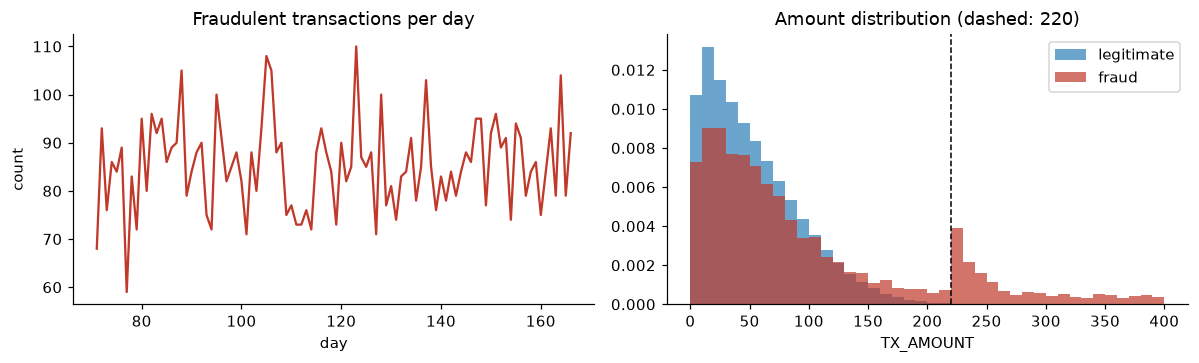

In [4]:
daily = df.groupby('TX_TIME_DAYS').agg(n=('TX_FRAUD','size'), fraud=('TX_FRAUD','sum'))
daily['rate'] = daily.fraud / daily.n
print(daily.describe().loc[['mean','std','min','max']].round(4))

scen = (df[df.TX_FRAUD==1].groupby('TX_FRAUD_SCENARIO')
        .agg(n_fraud=('TX_FRAUD','size'), min_amt=('TX_AMOUNT','min'), median_amt=('TX_AMOUNT','median'), max_amt=('TX_AMOUNT','max'),
             customers=('CUSTOMER_ID','nunique'), terminals=('TERMINAL_ID','nunique')))
scen.to_csv(f'{RES_DIR}/fraud_scenarios.csv'); display(scen.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(daily.index, daily.fraud, color='#c0392b'); ax[0].set_title('Fraudulent transactions per day'); ax[0].set_xlabel('day'); ax[0].set_ylabel('count')
bins = np.linspace(0, 400, 41)
ax[1].hist(df.loc[df.TX_FRAUD==0,'TX_AMOUNT'], bins=bins, alpha=.7, density=True, label='legitimate', color='#2c7fb8')
ax[1].hist(df.loc[df.TX_FRAUD==1,'TX_AMOUNT'], bins=bins, alpha=.7, density=True, label='fraud', color='#c0392b')
ax[1].axvline(220, ls='--', c='k', lw=1); ax[1].set_title('Amount distribution (dashed: 220)'); ax[1].set_xlabel('TX_AMOUNT'); ax[1].legend()
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/profile_daily_amount.png', bbox_inches='tight'); plt.show()

### 1.1 Outliers and a simple rule

In [5]:
a = df.TX_AMOUNT
q1, q3 = a.quantile([.25, .75]); iqr_hi = q3 + 1.5*(q3-q1)
z = (a - a.mean())/a.std()
rows = []
for name, mask in [('IQR rule (> Q3+1.5 IQR = %.1f)' % iqr_hi, a > iqr_hi), ('|z| > 3', z.abs() > 3), ('amount > 220', a > 220)]:
    rows.append({'rule': name, 'flagged': int(mask.sum()), 'precision': df.TX_FRAUD[mask].mean(),
                 'recall': df.TX_FRAUD[mask].sum()/df.TX_FRAUD.sum()})
rules = pd.DataFrame(rows); rules.to_csv(f'{RES_DIR}/simple_rules.csv', index=False); rules.round(4)

,rule,flagged,precision,recall
0,IQR rule (> Q3+1.5 IQR = 160.9),14466,0.1459,0.2575
1,|z| > 3,6392,0.3060,0.2387
2,amount > 220,1746,1.0000,0.2131


### 1.2 Benford's Law on transaction amounts
Benford's Law (data visualisation lecture) says first digits of naturally occurring amounts follow log10(1 + 1/d). We compare observed first-digit shares with that curve using the mean absolute deviation (MAD).

MAD vs Benford: {'all': 0.0211, 'legitimate': 0.0212, 'fraud': 0.0167} (MAD > 0.015 is non-conformity under Nigrini's thresholds)


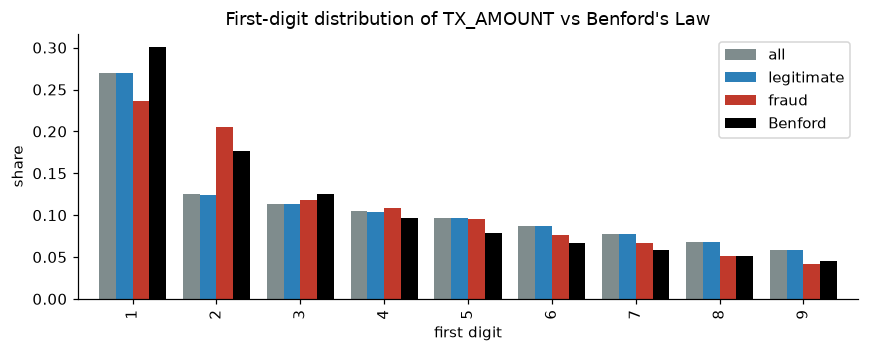

In [6]:
def first_digit(x):
    x = np.asarray(x, float); x = x[x > 0]
    return np.floor(x / 10**np.floor(np.log10(x))).astype(int)
benford = np.log10(1 + 1/np.arange(1, 10))
def digit_shares(x):
    d = first_digit(x); return np.bincount(d, minlength=10)[1:10] / len(d)
obs = {'all': digit_shares(df.TX_AMOUNT), 'legitimate': digit_shares(df.TX_AMOUNT[df.TX_FRAUD==0]), 'fraud': digit_shares(df.TX_AMOUNT[df.TX_FRAUD==1])}
ben = pd.DataFrame({k: v for k, v in obs.items()}, index=range(1, 10)); ben['Benford'] = benford
mad = {k: float(np.mean(np.abs(v - benford))) for k, v in obs.items()}
print('MAD vs Benford:', {k: round(v, 4) for k, v in mad.items()}, '(MAD > 0.015 is non-conformity under Nigrini\'s thresholds)')
ben.to_csv(f'{RES_DIR}/benford.csv')
ax = ben.plot(kind='bar', figsize=(8, 3.3), color=['#7f8c8d', '#2c7fb8', '#c0392b', 'k'], width=.8)
ax.set_xlabel('first digit'); ax.set_ylabel('share'); ax.set_title("First-digit distribution of TX_AMOUNT vs Benford's Law")
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/benford.png', bbox_inches='tight'); plt.show()

## 2. Delay-aware evaluation protocol
Fraud labels arrive late (a cardholder must notice and report). So for every fold we use the course set-up: **train window -> delay window -> test window**, and remove from the test set any card already known to be compromised. Folds slide forward in time; **fold 0 is used only to choose hyper-parameters**, and folds 1-3 are the untouched results.

In [7]:
def get_train_test_set(tx, start_date_training, delta_train=28, delta_delay=7, delta_test=7):
    # Adapted from the course notebook (04_Deep_Learning_Fraud_Detection).
    train_df = tx[(tx.TX_DATETIME >= start_date_training) &
                  (tx.TX_DATETIME < start_date_training + datetime.timedelta(days=delta_train))]
    known = set(train_df[train_df.TX_FRAUD == 1].CUSTOMER_ID)
    day0 = train_df.TX_TIME_DAYS.min()
    test_parts = []
    for day in range(delta_test):
        test_day = tx[tx.TX_TIME_DAYS == day0 + delta_train + delta_delay + day]
        prev = tx[tx.TX_TIME_DAYS == day0 + delta_train + day - 1]
        known = known.union(set(prev[prev.TX_FRAUD == 1].CUSTOMER_ID))
        test_parts.append(test_day[~test_day.CUSTOMER_ID.isin(known)])
    return train_df.sort_values('TRANSACTION_ID'), pd.concat(test_parts).sort_values('TRANSACTION_ID')

START = df.TX_DATETIME.min().normalize()
FOLD_OFFSETS = [0, 14, 28, 42]            # days after START; fold 0 = tuning fold
FOLDS = {i: get_train_test_set(df, START + pd.Timedelta(days=o)) for i, o in enumerate(FOLD_OFFSETS)}
fold_info = pd.DataFrame([{'fold': i, 'train_rows': len(tr), 'train_fraud': int(tr.TX_FRAUD.sum()),
                           'test_rows': len(te), 'test_fraud': int(te.TX_FRAUD.sum()),
                           'train_from': tr.TX_DATETIME.min().date(), 'test_to': te.TX_DATETIME.max().date()}
                          for i, (tr, te) in FOLDS.items()])
fold_info.to_csv(f'{RES_DIR}/folds.csv', index=False); fold_info

,fold,train_rows,train_fraud,test_rows,test_fraud,train_from,test_to
0,0,268885,2384,45874,258,2018-06-11,2018-07-22
1,1,268366,2407,47004,286,2018-06-25,2018-08-05
2,2,267802,2392,47189,293,2018-07-09,2018-08-19
3,3,268140,2372,46817,312,2018-07-23,2018-09-02


In [8]:
K = 100   # daily review budget (cards for Card Precision@k, transactions for recall)
def evaluate(test_df, scores, k=K):
    t = test_df[['TX_FRAUD','CUSTOMER_ID','TX_TIME_DAYS','TX_AMOUNT']].copy(); t['score'] = np.asarray(scores)
    cp, rec, amt, tp, flagged = [], [], [], 0, 0
    for _, g in t.groupby('TX_TIME_DAYS'):
        gc = g.groupby('CUSTOMER_ID').agg(score=('score','max'), fraud=('TX_FRAUD','max')).sort_values('score', ascending=False).head(k)
        cp.append(gc.fraud.sum() / k)
        top = g.nlargest(k, 'score'); nf = g.TX_FRAUD.sum()
        tp += int(top.TX_FRAUD.sum()); flagged += len(top)
        if nf > 0:
            rec.append(top.TX_FRAUD.sum() / nf)
            amt.append(top.loc[top.TX_FRAUD==1,'TX_AMOUNT'].sum() / g.loc[g.TX_FRAUD==1,'TX_AMOUNT'].sum())
    return {'AUC': roc_auc_score(t.TX_FRAUD, t.score), 'AP': average_precision_score(t.TX_FRAUD, t.score),
            f'CardPrec@{k}': float(np.mean(cp)), f'Recall@{k}tx': float(np.mean(rec)), f'AmountRecall@{k}tx': float(np.mean(amt)),
            'TP': tp, 'Flagged': flagged}

LOG_COLS = ['TX_AMOUNT','CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW','CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW','CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW']
def prep_dense(train, test, only_legit_fit=False):
    # log1p for skewed amount columns (course notebook), then standardise with train statistics only.
    def tf(d):
        X = d[FEATURES].copy()
        for c in LOG_COLS: X[c] = np.log1p(X[c].clip(lower=0))
        return X.values
    Xtr, Xte = tf(train), tf(test)
    sc = StandardScaler().fit(Xtr[(train.TX_FRAUD == 0).values] if only_legit_fit else Xtr)
    return sc.transform(Xtr), sc.transform(Xte)

## 3. Models
Each model produces a **risk score** per transaction. All models are fitted on the train window only.

In [9]:
def fit_rule(train, test, **kw):            # baseline: bigger amount = riskier
    return test.TX_AMOUNT.values

def fit_logreg(train, test, penalty='l2', C=1.0, **kw):
    Xtr, Xte = prep_dense(train, test)
    m = LogisticRegression(penalty=penalty, C=C, solver='liblinear', class_weight='balanced', max_iter=200, random_state=SEED)
    m.fit(Xtr, train.TX_FRAUD.values); return m.decision_function(Xte), m

def fit_mlp(train, test, hidden=(64, 32), alpha=1e-4, seed=SEED, **kw):
    Xtr, Xte = prep_dense(train, test)
    m = MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, batch_size=256, learning_rate_init=1e-3, max_iter=25,
                      early_stopping=True, n_iter_no_change=3, random_state=seed)
    m.fit(Xtr, train.TX_FRAUD.values); return m.predict_proba(Xte)[:, 1], m

def fit_autoencoder(train, test, hidden=(8, 4, 8), **kw):
    # Unsupervised: learn to reconstruct LEGITIMATE transactions only; high reconstruction error = anomaly.
    Xtr, Xte = prep_dense(train, test, only_legit_fit=True)
    Xleg = Xtr[(train.TX_FRAUD == 0).values]
    m = MLPRegressor(hidden_layer_sizes=hidden, batch_size=256, learning_rate_init=1e-3, max_iter=20,
                     early_stopping=True, n_iter_no_change=3, random_state=SEED)
    m.fit(Xleg, Xleg); return ((m.predict(Xte) - Xte) ** 2).mean(axis=1), m

def fit_lgbm(train, test, num_leaves=31, spw=1.0, features=None, seed=SEED, **kw):
    feats = features or FEATURES
    m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=num_leaves, min_child_samples=50, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, scale_pos_weight=spw, random_state=seed, n_jobs=2, verbose=-1)
    m.fit(train[feats], train.TX_FRAUD); return m.predict_proba(test[feats])[:, 1], m

def run(fn, fold, **kw):
    tr, te = FOLDS[fold]; t0 = time.time(); out = fn(tr, te, **kw)
    scores, model = (out if isinstance(out, tuple) else (out, None))
    r = evaluate(te, scores); r['seconds'] = round(time.time() - t0, 1); return r, scores, model

### 3.1 Hyper-parameters (fold 0 only, chosen by Average Precision)

In [10]:
GRIDS = {
  'LogReg': (fit_logreg, [{'penalty': p, 'C': c} for p in ('l1', 'l2') for c in (0.01, 0.1, 1.0)]),
  'FFNN': (fit_mlp, [{'hidden': h, 'alpha': a} for h in ((32,), (64, 32)) for a in (1e-4, 1e-2)]),
  'Autoencoder': (fit_autoencoder, [{'hidden': h} for h in ((8, 4, 8), (12, 6, 3, 6, 12))]),
  'LightGBM': (fit_lgbm, [{'num_leaves': n, 'spw': s} for n in (15, 63) for s in (1.0, 10.0)]),
}
tuning, best = [], {}
for name, (fn, grid) in GRIDS.items():
    for params in grid:
        r, _, _ = run(fn, 0, **params); tuning.append({'model': name, 'params': str(params), **{k: r[k] for k in ('AUC','AP','CardPrec@100','seconds')}})
    t = pd.DataFrame([x for x in tuning if x['model'] == name]); bi = t.AP.idxmax()
    best[name] = grid[list(t.index).index(bi)]
tuning = pd.DataFrame(tuning); tuning.to_csv(f'{RES_DIR}/tuning_fold0.csv', index=False)
print('Chosen:', best); tuning.round(4)

Chosen: {'LogReg': {'penalty': 'l1', 'C': 0.01}, 'FFNN': {'hidden': (64, 32), 'alpha': 0.01}, 'Autoencoder': {'hidden': (12, 6, 3, 6, 12)}, 'LightGBM': {'num_leaves': 63, 'spw': 1.0}}


,model,params,AUC,AP,CardPrec@100,seconds
0,LogReg,"{'penalty': 'l1', 'C': 0.01}",0.8873,0.4250,0.2229,2.0
1,LogReg,"{'penalty': 'l1', 'C': 0.1}",0.8873,0.4244,0.2214,2.1
2,LogReg,"{'penalty': 'l1', 'C': 1.0}",0.8873,0.4243,0.2229,2.1
3,LogReg,"{'penalty': 'l2', 'C': 0.01}",0.8872,0.4236,0.2257,0.3
4,LogReg,"{'penalty': 'l2', 'C': 0.1}",0.8873,0.4246,0.2229,0.3
5,LogReg,"{'penalty': 'l2', 'C': 1.0}",0.8873,0.4243,0.2229,0.3
6,FFNN,"{'hidden': (32,), 'alpha': 0.0001}",0.8900,0.6466,0.2414,2.0
7,FFNN,"{'hidden': (32,), 'alpha': 0.01}",0.8885,0.6596,0.2471,2.1
8,FFNN,"{'hidden': (64, 32), 'alpha': 0.0001}",0.8790,0.6823,0.2471,2.3
9,FFNN,"{'hidden': (64, 32), 'alpha': 0.01}",0.8800,0.6989,0.2486,2.3


## 4. Results on untouched folds 1-3

In [11]:
MODELS = {'Amount rule': (fit_rule, {}), **{n: (GRIDS[n][0], best[n]) for n in GRIDS}}
rows, scores_store, models_store = [], {}, {}
for name, (fn, params) in MODELS.items():
    for fold in (1, 2, 3):
        r, s, m = run(fn, fold, **params); rows.append({'model': name, 'fold': fold, **r})
        scores_store[(name, fold)] = s; models_store[(name, fold)] = m
res = pd.DataFrame(rows); res.to_csv(f'{RES_DIR}/results_by_fold.csv', index=False)
METRICS = ['AUC', 'AP', 'CardPrec@100', 'Recall@100tx', 'AmountRecall@100tx']
agg = res.groupby('model')[METRICS + ['seconds']].agg(['mean', 'std'])
table = pd.DataFrame({m: res.groupby('model')[m].mean() for m in METRICS}); table['train_sec'] = res.groupby('model').seconds.mean()
table = table.loc[['Amount rule', 'LogReg', 'FFNN', 'Autoencoder', 'LightGBM']]
table.to_csv(f'{RES_DIR}/results_summary.csv'); agg.to_csv(f'{RES_DIR}/results_mean_std.csv')
table.round(3)

,AUC,AP,CardPrec@100,Recall@100tx,AmountRecall@100tx,train_sec
model,,,,,,
Amount rule,0.627,0.213,0.095,0.231,0.630,0.000
LogReg,0.866,0.506,0.258,0.666,0.759,2.000
FFNN,0.874,0.676,0.281,0.719,0.849,2.400
Autoencoder,0.770,0.314,0.173,0.398,0.195,4.200
LightGBM,0.867,0.674,0.279,0.714,0.856,2.433


In [12]:
std = pd.DataFrame({m: res.groupby('model')[m].std() for m in METRICS}).loc[table.index]
print('Std. dev. across the 3 test folds (n=3, so indicative only):'); std.round(3)

Std. dev. across the 3 test folds (n=3, so indicative only):


,AUC,AP,CardPrec@100,Recall@100tx,AmountRecall@100tx
model,,,,,
Amount rule,0.011,0.018,0.011,0.009,0.026
LogReg,0.016,0.033,0.016,0.037,0.015
FFNN,0.019,0.029,0.021,0.040,0.030
Autoencoder,0.016,0.048,0.010,0.008,0.008
LightGBM,0.023,0.042,0.028,0.054,0.046


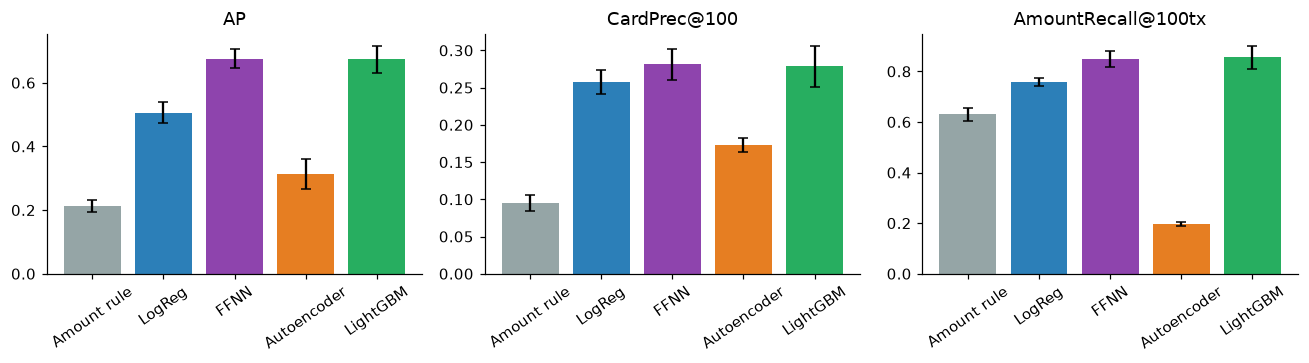

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
cols = {'Amount rule': '#95a5a6', 'LogReg': '#2c7fb8', 'FFNN': '#8e44ad', 'Autoencoder': '#e67e22', 'LightGBM': '#27ae60'}
for a, m in zip(ax, ['AP', 'CardPrec@100', 'AmountRecall@100tx']):
    a.bar(table.index, table[m], yerr=std[m], color=[cols[i] for i in table.index], capsize=3)
    a.set_title(m); a.tick_params(axis='x', rotation=35)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/model_comparison.png', bbox_inches='tight'); plt.show()

In [14]:
# Upper bound for Card Precision@100: on a day with fewer than 100 compromised cards, even a perfect model cannot reach 1.0.
ceil = []
for fold in (1, 2, 3):
    te = FOLDS[fold][1]; cards = te[te.TX_FRAUD == 1].groupby('TX_TIME_DAYS').CUSTOMER_ID.nunique()
    ceil.append({'fold': fold, 'fraud_cards_per_day': cards.mean(), 'max_CardPrec@100': float(np.minimum(cards, K).mean() / K)})
ceil = pd.DataFrame(ceil); ceil.to_csv(f'{RES_DIR}/cardprec_ceiling.csv', index=False)
print('Mean achievable ceiling:', round(ceil['max_CardPrec@100'].mean(), 3)); ceil.round(3)

Mean achievable ceiling: 0.388


,fold,fraud_cards_per_day,max_CardPrec@100
0,1,36.857,0.369
1,2,38.143,0.381
2,3,41.429,0.414


### 4.1 What do the models rely on? (interpretability)

In [15]:
lr = models_store[('LogReg', 3)]
coef = pd.Series(lr.coef_[0], index=FEATURES).sort_values(key=abs, ascending=False)
gbm = models_store[('LightGBM', 3)]
imp = pd.Series(gbm.booster_.feature_importance('gain'), index=FEATURES); imp = (imp / imp.sum()).sort_values(ascending=False)
interp = pd.DataFrame({'logreg_coef_(std. features)': coef, 'lightgbm_gain_share': imp}).sort_values('lightgbm_gain_share', ascending=False)
interp.to_csv(f'{RES_DIR}/feature_importance_fold3.csv'); interp.round(3).head(10)

,logreg_coef_(std. features),lightgbm_gain_share
TERMINAL_ID_RISK_7DAY_WINDOW,0.637,0.268
TX_AMOUNT,0.723,0.211
TERMINAL_ID_RISK_30DAY_WINDOW,-0.169,0.131
CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,3.052,0.091
CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,-3.752,0.081
CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,0.392,0.053
CUSTOMER_ID_NB_TX_30DAY_WINDOW,-0.007,0.043
TERMINAL_ID_NB_TX_30DAY_WINDOW,-0.014,0.034
CUSTOMER_ID_NB_TX_7DAY_WINDOW,-0.003,0.026
TERMINAL_ID_NB_TX_7DAY_WINDOW,0.039,0.022


In [16]:
sc = scen.copy()
te3 = FOLDS[3][1].copy(); te3['score'] = scores_store[('LightGBM', 3)]
# Which fraud scenarios does the best model rank highly? (analysis only; scenario is not a model input)
thr = te3.groupby('TX_TIME_DAYS').score.transform(lambda s: s.nlargest(K).min())
te3['flagged'] = te3.score >= thr
by_scen = te3[te3.TX_FRAUD==1].groupby('TX_FRAUD_SCENARIO').agg(n_fraud=('flagged','size'), caught_in_top100=('flagged','sum'))
by_scen['caught_share'] = by_scen.caught_in_top100 / by_scen.n_fraud
by_scen.to_csv(f'{RES_DIR}/lightgbm_by_scenario_fold3.csv'); by_scen.round(3)

,n_fraud,caught_in_top100,caught_share
TX_FRAUD_SCENARIO,,,
1,22,22,1.000
2,221,142,0.643
3,69,65,0.942


## 5. Social-network feature: personalised PageRank
The SNA lecture uses PageRank with a restart vector on a semi-labelled network to spread fraud "suspicion". We build a **customer-terminal bipartite graph** (an edge for every pair that transacted), seed the restart vector on customers and terminals involved in *known* fraud, and use the resulting scores as features.

To avoid leaking labels into training rows, features for training rows come from the **earlier half** of the train window, and test features from the **later half** (same 14-day length, same label delay logic).

In [17]:
N_C, N_T = 5000, 10000
def ppr_features(window, alpha=0.85, iters=60):
    # window: transactions used for graph structure AND fraud seeds (labels known by then)
    c = window.CUSTOMER_ID.values; t = N_C + window.TERMINAL_ID.values
    A = sp.coo_matrix((np.ones(len(window)), (c, t)), shape=(N_C + N_T, N_C + N_T)).tocsr()
    A = A + A.T
    deg = np.asarray(A.sum(1)).ravel(); deg[deg == 0] = 1
    P = sp.diags(1 / deg) @ A                       # row-stochastic
    fr = window[window.TX_FRAUD == 1]
    v = np.zeros(N_C + N_T)
    np.add.at(v, fr.CUSTOMER_ID.values, 1.0); np.add.at(v, N_C + fr.TERMINAL_ID.values, 1.0)
    if v.sum() == 0: return v[:N_C], v[N_C:]
    v /= v.sum(); r = v.copy()
    for _ in range(iters): r = alpha * (P.T @ r) + (1 - alpha) * v
    return r[:N_C], r[N_C:]

def add_ppr(rows, window):
    pc, pt = ppr_features(window); out = rows.copy()
    out['PPR_CUSTOMER'] = pc[out.CUSTOMER_ID.values] * 1e4; out['PPR_TERMINAL'] = pt[out.TERMINAL_ID.values] * 1e4
    return out

GRAPH_FEATS = FEATURES + ['PPR_CUSTOMER', 'PPR_TERMINAL']
lgbm_cfg = best['LightGBM']; g_rows = []; g_scores = {}
for fold in (1, 2, 3):
    tr, te = FOLDS[fold]; mid = tr.TX_DATETIME.min() + pd.Timedelta(days=14)
    A_win, B_win = tr[tr.TX_DATETIME < mid], tr[tr.TX_DATETIME >= mid]
    trainB_graph, test_graph = add_ppr(B_win, A_win), add_ppr(te, B_win)
    for label, feats, trn, tst in [('LightGBM (latest 14d)', FEATURES, B_win, te),
                                    ('LightGBM + PageRank (latest 14d)', GRAPH_FEATS, trainB_graph, test_graph)]:
        t0 = time.time(); s, m = fit_lgbm(trn, tst, features=feats, **lgbm_cfg)
        r = evaluate(te, s); r.update({'model': label, 'fold': fold, 'seconds': round(time.time() - t0, 1)}); g_rows.append(r); g_scores[(label, fold)] = s
gres = pd.DataFrame(g_rows); gres.to_csv(f'{RES_DIR}/graph_ablation_by_fold.csv', index=False)
gsum = gres.groupby('model')[METRICS].mean(); gsum.to_csv(f'{RES_DIR}/graph_ablation_summary.csv'); gsum.round(3)

,AUC,AP,CardPrec@100,Recall@100tx,AmountRecall@100tx
model,,,,,
LightGBM (latest 14d),0.874,0.663,0.279,0.708,0.854
LightGBM + PageRank (latest 14d),0.876,0.633,0.271,0.683,0.836


In [18]:
gd = gres.pivot(index='fold', columns='model', values='AP'); gd['delta'] = gd['LightGBM + PageRank (latest 14d)'] - gd['LightGBM (latest 14d)']
print('Average Precision per fold, with vs without PageRank features:'); gd.round(4)

Average Precision per fold, with vs without PageRank features:


model,LightGBM (latest 14d),LightGBM + PageRank (latest 14d),delta
fold,,,
1,0.6929,0.6279,-0.0650
2,0.6172,0.6045,-0.0127
3,0.6784,0.6656,-0.0128


## 6. Business integration: a daily review queue
Analysts can review only a fixed number of cases per day. Here we ask: if the best model ranks transactions and analysts review the top **K = 100 per day**, how much fraud do they catch and what does that cost?

*Assumption (not in the data):* each review costs `REVIEW_COST` currency units. Change it to match your own operating cost. A review that finds fraud recovers the transaction amount.

In [19]:
REVIEW_COST = 5.0
def queue_view(name, fold):
    te = FOLDS[fold][1].copy(); te['score'] = scores_store[(name, fold)]
    days = te.TX_TIME_DAYS.nunique(); rows = []
    for _, g in te.groupby('TX_TIME_DAYS'):
        top = g.nlargest(K, 'score')
        rows.append((top.TX_FRAUD.sum(), K - top.TX_FRAUD.sum(), g.TX_FRAUD.sum() - top.TX_FRAUD.sum(),
                     top.loc[top.TX_FRAUD == 1, 'TX_AMOUNT'].sum(), g.loc[g.TX_FRAUD == 1, 'TX_AMOUNT'].sum()))
    a = np.array(rows).mean(0)
    return {'model': name, 'fold': fold, 'caught/day': a[0], 'false_alerts/day': a[1], 'missed/day': a[2], 'amount_caught/day': a[3],
            'amount_total/day': a[4], 'review_cost/day': K * REVIEW_COST, 'net_benefit/day': a[3] - K * REVIEW_COST}
q = pd.DataFrame([queue_view(n, f) for n in ['Amount rule', 'LogReg', 'FFNN', 'Autoencoder', 'LightGBM'] for f in (1, 2, 3)])
qs = q.groupby('model').mean(numeric_only=True).drop(columns='fold').loc[['Amount rule', 'LogReg', 'FFNN', 'Autoencoder', 'LightGBM']]
qs.to_csv(f'{RES_DIR}/review_queue_summary.csv'); qs.round(1)

,caught/day,false_alerts/day,missed/day,amount_caught/day,amount_total/day,review_cost/day,net_benefit/day
model,,,,,,,
Amount rule,9.7,90.3,32.7,3094.4,4814.6,500.0,2594.4
LogReg,28.0,72.0,14.4,3646.3,4814.6,500.0,3146.3
FFNN,30.4,69.6,12.0,4116.6,4814.6,500.0,3616.6
Autoencoder,16.9,83.1,25.6,906.6,4814.6,500.0,406.6
LightGBM,30.3,69.7,12.1,4161.4,4814.6,500.0,3661.4


In [20]:
# Sensitivity of net benefit to review cost, best model vs amount rule
sens = []
for rc in (1, 5, 10, 25, 50):
    for n in ('Amount rule', 'LightGBM'):
        s = q[q.model == n]; sens.append({'review_cost': rc, 'model': n, 'net_benefit/day': (s['amount_caught/day'] - K * rc).mean()})
sens = pd.DataFrame(sens).pivot(index='review_cost', columns='model', values='net_benefit/day'); sens.to_csv(f'{RES_DIR}/review_cost_sensitivity.csv'); sens.round(0)

model,Amount rule,LightGBM
review_cost,,
1,2994.0,4061.0
5,2594.0,3661.0
10,2094.0,3161.0
25,594.0,1661.0
50,-1906.0,-839.0


### 6.1 How big should the queue be? K trade-off and the false-alarm floor
On a day with `n` fraudulent transactions, at most `min(K, n)` of the top K can be fraud, so even a perfect ranker raises `K - min(K, n)` false alerts. With about 42 frauds per test day, roughly 58 of 100 alerts are false **whatever the model**. Here we vary K and measure each model against that reachable maximum instead of against K.

Nothing is tuned here: the models and their settings come from Section 3.1, the K values are fixed in advance, and only the test-fold scores from Section 4 are reused. Ties are broken with `nlargest`, as in `queue_view`, so the K = 100 rows match the table above.

In [21]:
K_GRID = [25, 50, 100, 150]
kt = []
for name in ('FFNN', 'LightGBM'):
    for fold in (1, 2, 3):
        te = FOLDS[fold][1][['TX_TIME_DAYS', 'TX_FRAUD', 'TX_AMOUNT']].copy(); te['score'] = scores_store[(name, fold)]
        for day, g in te.groupby('TX_TIME_DAYS'):
            nf = int(g.TX_FRAUD.sum())
            for k in K_GRID:
                top = g.nlargest(k, 'score'); caught = int(top.TX_FRAUD.sum()); reach = min(k, nf)
                amt = top.loc[top.TX_FRAUD == 1, 'TX_AMOUNT'].sum()
                kt.append({'model': name, 'fold': fold, 'day': day, 'K': k, 'frauds_that_day': nf,
                           'caught/day': caught, 'false_alerts/day': k - caught,
                           'reachable/day': reach, 'unavoidable_false/day': k - reach,
                           'precision@K': caught / k, 'recall@K': caught / nf if nf else np.nan,
                           'share_of_reachable': caught / reach if reach else np.nan,
                           'amount_caught/day': amt, 'net_benefit/day': amt - k * REVIEW_COST})
kt = pd.DataFrame(kt)
kt_fold = kt.groupby(['model', 'K', 'fold']).mean(numeric_only=True).drop(columns='day').reset_index()
kt_fold.to_csv(f'{RES_DIR}/k_tradeoff_by_fold.csv', index=False)
kt_sum = kt_fold.groupby(['model', 'K']).mean(numeric_only=True).drop(columns='fold').reset_index()
kt_sum['share_of_reachable_std'] = kt_fold.groupby(['model', 'K']).share_of_reachable.std().values
# marginal precision: extra frauds caught per extra alert when K grows from the previous value in K_GRID
kt_sum['marginal_precision'] = kt_sum.groupby('model')['caught/day'].diff() / kt_sum.groupby('model')['K'].diff()
kt_sum = kt_sum.set_index(['model', 'K'])
kt_sum.to_csv(f'{RES_DIR}/k_tradeoff_summary.csv')

# consistency check against the Section 6 queue table (same scores, same tie-breaking)
for name in ('FFNN', 'LightGBM'):
    assert np.isclose(kt_sum.loc[(name, 100), 'caught/day'], qs.loc[name, 'caught/day'])
    assert np.isclose(kt_sum.loc[(name, 100), 'net_benefit/day'], qs.loc[name, 'net_benefit/day'])
kt_sum[['frauds_that_day', 'caught/day', 'false_alerts/day', 'unavoidable_false/day', 'precision@K', 'recall@K',
        'share_of_reachable', 'share_of_reachable_std', 'marginal_precision', 'net_benefit/day']].round(3)

frauds_that_day  caught/day  false_alerts/day  \
model    K                                                    
FFNN     25            42.429      22.857             2.143   
         50            42.429      28.286            21.714   
         100           42.429      30.381            69.619   
         150           42.429      30.905           119.095   
LightGBM 25            42.429      22.762             2.238   
         50            42.429      28.810            21.190   
         100           42.429      30.286            69.714   
         150           42.429      30.619           119.381   

              unavoidable_false/day  precision@K  recall@K  \
model    K                                                   
FFNN     25                   0.000        0.914     0.548   
         50                   8.524        0.566     0.669   
         100                 57.571        0.304     0.719   
         150                107.571        0.206     0.730   
LightGBM 25                   0.000        0.910     0.546   
         50                   8.524        0.576     0.680   
         100                 57.571        0.303     0.714   
         150                107.571        0.204     0.723   

              share_of_reachable  share_of_reachable_std  marginal_precision  \
model    K                                                                     
FFNN     25                0.914                   0.043                 NaN   
         50                0.680                   0.037               0.217   
         100               0.719                   0.040               0.042   
         150               0.730                   0.044               0.010   
LightGBM 25                0.910                   0.063                 NaN   
         50                0.692                   0.046               0.242   
         100               0.714                   0.054               0.030   
         150               0.723                   0.052               0.007   

              net_benefit/day  
model    K                     
FFNN     25          3131.858  
         50          3641.037  
         100         3616.575  
         150         3432.186  
LightGBM 25          2858.019  
         50          3728.839  
         100         3661.435  
         150         3436.705

### 6.2 Does the autoencoder add anything to the supervised network? (FFNN + autoencoder ensemble)
The autoencoder alone is weak (Section 4), but it needs no labels and might catch cases the network misses. We blend the two:

`score = (1 - w) * rank(FFNN) + w * rank(autoencoder)`

where `rank` is the within-day percentile rank (0 to 1). Ranks are needed because the two scores are on different scales (probability vs reconstruction error), and within-day ranks match how the daily queue is built. **w is chosen from {0, 0.1, 0.25, 0.5} on fold 0 by AP**; folds 1-3 only report the chosen w against w = 0 (the network alone). Fold-0 scores are not in `scores_store`, so both models are refitted on fold 0 with their chosen settings (deterministic, so the FFNN fit is identical to the one in the tuning grid).

In [22]:
ENS_W = [0, 0.1, 0.25, 0.5]
def day_rank(test_df, s):
    # percentile rank of each score within its own day (0 to 1]
    return pd.Series(np.asarray(s), index=test_df.index).groupby(test_df.TX_TIME_DAYS.values).rank(pct=True).values

ens_rank, ens_raw = {}, {}
for fold in (0, 1, 2, 3):
    te = FOLDS[fold][1]
    if fold == 0:
        f_s = run(fit_mlp, 0, **best['FFNN'])[1]; a_s = run(fit_autoencoder, 0, **best['Autoencoder'])[1]
    else:
        f_s, a_s = scores_store[('FFNN', fold)], scores_store[('Autoencoder', fold)]
    ens_rank[fold] = (day_rank(te, f_s), day_rank(te, a_s)); ens_raw[fold] = f_s
# the refitted fold-0 network must reproduce the tuning-grid result
assert np.isclose(average_precision_score(FOLDS[0][1].TX_FRAUD, ens_raw[0]),
                  tuning.loc[(tuning.model == 'FFNN') & (tuning.params == str(best['FFNN'])), 'AP'].item())

ens = pd.DataFrame([{'fold': fold, 'w': w, **evaluate(FOLDS[fold][1], (1 - w) * rf + w * ra)}
                    for fold, (rf, ra) in ens_rank.items() for w in ENS_W])
ens.to_csv(f'{RES_DIR}/ensemble_by_fold.csv', index=False)
tune0 = ens[ens.fold == 0].set_index('w')
best_w = float(tune0.AP.idxmax())                      # ties -> smaller w (idxmax keeps the first)
print('Fold 0 (selection):'); display(tune0[METRICS].round(4))
print(f'Chosen w = {best_w}')

test = ens[ens.fold > 0]
ens_sum = test.groupby('w')[METRICS].agg(['mean', 'std'])
ens_sum.to_csv(f'{RES_DIR}/ensemble_test_summary.csv')
# Per-fold AP difference of every blend against the network alone (w = 0). Not used for selection.
base = test[test.w == 0].set_index('fold')
paired = pd.concat({w: test[test.w == w].set_index('fold')[METRICS] - base[METRICS] for w in ENS_W if w > 0}, names=['w'])
paired.to_csv(f'{RES_DIR}/ensemble_paired_diff.csv')
print('Folds 1-3, all w (only the chosen w is a result; the others are shown for transparency):')
display(test.groupby('w')[METRICS].mean().round(4))
print('Difference per fold, each blend minus the network alone (w = 0):'); paired.round(4)

Fold 0 (selection):


,AUC,AP,CardPrec@100,Recall@100tx,AmountRecall@100tx
w,,,,,
0.00,0.8799,0.6820,0.2486,0.7434,0.8784
0.10,0.8741,0.5013,0.2171,0.6058,0.6116
0.25,0.8648,0.4441,0.1857,0.5073,0.4441
0.50,0.8443,0.4017,0.1743,0.4677,0.3662


Chosen w = 0.0
Folds 1-3, all w (only the chosen w is a result; the others are shown for transparency):


,AUC,AP,CardPrec@100,Recall@100tx,AmountRecall@100tx
w,,,,,
0.00,0.8728,0.6652,0.2814,0.7186,0.8489
0.10,0.8704,0.5472,0.2605,0.6503,0.7159
0.25,0.8657,0.4873,0.2386,0.5639,0.5264
0.50,0.8552,0.4452,0.2152,0.4885,0.3715


Difference per fold, each blend minus the network alone (w = 0):


AUC      AP  CardPrec@100  Recall@100tx  AmountRecall@100tx
w    fold                                                                
0.10 1    -0.0026 -0.1290       -0.0214       -0.0751             -0.1654
     2    -0.0023 -0.1047       -0.0186       -0.0713             -0.1349
     3    -0.0023 -0.1201       -0.0229       -0.0586             -0.0988
0.25 1    -0.0073 -0.2001       -0.0443       -0.1709             -0.3203
     2    -0.0069 -0.1508       -0.0314       -0.1464             -0.3095
     3    -0.0071 -0.1826       -0.0529       -0.1470             -0.3377
0.50 1    -0.0178 -0.2489       -0.0629       -0.2526             -0.4858
     2    -0.0158 -0.1822       -0.0486       -0.1960             -0.4311
     3    -0.0193 -0.2287       -0.0871       -0.2417             -0.5153

### 6.3 Is the FFNN-LightGBM tie real? Five random seeds
All results above use one seed (42). Here both models are refitted with their chosen settings (Section 3.1, unchanged) for seeds 0-4 on each test fold: 15 runs per model. The seed controls weight initialisation, mini-batch order and the early-stopping split for the network, and row and column subsampling for LightGBM.

We report the mean and standard deviation over the 15 runs, how much of the spread comes from the seed versus the test week, and the paired difference FFNN − LightGBM for each fold and seed. Pairing by fold is what matters (both models face the same week); pairing by seed number is arbitrary, because seed 0 means different things in the two libraries.

In [23]:
SEEDS = [0, 1, 2, 3, 4]
SM = METRICS + ['caught/day']
seed_rows = []
for name, fn in (('FFNN', fit_mlp), ('LightGBM', fit_lgbm)):
    for fold in (1, 2, 3):
        days = FOLDS[fold][1].TX_TIME_DAYS.nunique()
        for s in SEEDS:
            r, _, _ = run(fn, fold, seed=s, **best[name])
            seed_rows.append({'model': name, 'fold': fold, 'seed': s, **r, 'caught/day': r['TP'] / days})
seeds = pd.DataFrame(seed_rows); seeds.to_csv(f'{RES_DIR}/seed_runs.csv', index=False)

seed_sum = seeds.groupby('model')[SM].agg(['mean', 'std'])                  # over all 15 runs per model
seed_sum.to_csv(f'{RES_DIR}/seed_summary.csv')
spread = pd.concat({'seed_std_within_fold': seeds.groupby(['model', 'fold'])[SM].std().groupby('model').mean(),
                    'std_of_fold_means': seeds.groupby(['model', 'fold'])[SM].mean().groupby('model').std()}, names=['source'])
spread.to_csv(f'{RES_DIR}/seed_spread.csv')

wide = seeds.pivot_table(index=['fold', 'seed'], columns='model', values=SM)
diff = pd.DataFrame({m: wide[(m, 'FFNN')] - wide[(m, 'LightGBM')] for m in SM})   # FFNN minus LightGBM
diff.to_csv(f'{RES_DIR}/seed_paired_diff.csv')
diff_sum = pd.DataFrame({'mean': diff.mean(), 'std': diff.std(), 'min': diff.min(), 'max': diff.max(),
                         'FFNN_better_of_15': (diff > 0).sum(),
                         **{f'fold{f}_mean': diff.xs(f, level='fold').mean() for f in (1, 2, 3)}})
diff_sum.to_csv(f'{RES_DIR}/seed_paired_summary.csv')
print('Mean (std) over 15 runs:'); display(seed_sum.round(4))
print('Where the spread comes from:'); display(spread.round(4))
print('Paired difference FFNN - LightGBM (positive = FFNN better):'); diff_sum.round(4)

Mean (std) over 15 runs:


AUC              AP         CardPrec@100         Recall@100tx  \
            mean     std    mean     std         mean     std         mean   
model                                                                        
FFNN      0.8726  0.0159  0.6781  0.0320       0.2794  0.0197       0.7140   
LightGBM  0.8687  0.0200  0.6768  0.0356       0.2819  0.0217       0.7233   

                 AmountRecall@100tx         caught/day          
             std               mean     std       mean     std  
model                                                           
FFNN      0.0418             0.8481  0.0261    30.1905  1.8903  
LightGBM  0.0447             0.8616  0.0376    30.6000  1.9500

Where the spread comes from:


AUC      AP  CardPrec@100  Recall@100tx  \
source               model                                                  
seed_std_within_fold FFNN      0.0035  0.0076        0.0039        0.0097   
                     LightGBM  0.0030  0.0032        0.0024        0.0049   
std_of_fold_means    FFNN      0.0184  0.0370        0.0229        0.0483   
                     LightGBM  0.0234  0.0420        0.0255        0.0526   

                               AmountRecall@100tx  caught/day  
source               model                                     
seed_std_within_fold FFNN                  0.0088      0.4058  
                     LightGBM              0.0043      0.2068  
std_of_fold_means    FFNN                  0.0290      2.1913  
                     LightGBM              0.0442      2.2941

Paired difference FFNN - LightGBM (positive = FFNN better):


,mean,std,min,max,FFNN_better_of_15,fold1_mean,fold2_mean,fold3_mean
AUC,0.0039,0.0071,-0.0073,0.0143,11,0.0040,0.0104,-0.0026
AP,0.0013,0.0089,-0.0162,0.0157,9,0.0006,0.0078,-0.0046
CardPrec@100,-0.0025,0.0057,-0.0157,0.0086,3,-0.0040,0.0009,-0.0043
Recall@100tx,-0.0093,0.0109,-0.0292,0.0100,4,-0.0138,-0.0050,-0.0092
AmountRecall@100tx,-0.0135,0.0165,-0.0374,0.0088,4,-0.0243,0.0041,-0.0203
caught/day,-0.4095,0.4641,-1.2857,0.4286,2,-0.6000,-0.2286,-0.4000


## 7. Summary of outputs
All tables are saved in `results/` and figures in `figures/`. The report quotes these files directly.

In [24]:
for f in sorted(os.listdir(RES_DIR)): print(f'results/{f}')
for f in sorted(os.listdir(FIG_DIR)): print(f'figures/{f}')

results/benford.csv
results/cardprec_ceiling.csv
results/ensemble_by_fold.csv
results/ensemble_paired_diff.csv
results/ensemble_test_summary.csv
results/feature_importance_fold3.csv
results/folds.csv
results/fraud_scenarios.csv
results/graph_ablation_by_fold.csv
results/graph_ablation_summary.csv
results/k_tradeoff_by_fold.csv
results/k_tradeoff_summary.csv
results/lightgbm_by_scenario_fold3.csv
results/results_by_fold.csv
results/results_mean_std.csv
results/results_summary.csv
results/review_cost_sensitivity.csv
results/review_queue_summary.csv
results/seed_paired_diff.csv
results/seed_paired_summary.csv
results/seed_runs.csv
results/seed_spread.csv
results/seed_summary.csv
results/simple_rules.csv
results/tuning_fold0.csv
results/variable_summary.csv
figures/benford.png
figures/model_comparison.png
figures/profile_daily_amount.png
